# Why six activation clusters, and does the number matter?

The paper groups the 687 odorants with at least one call into six clusters by k-medoids on the
Jaccard distance between their receptor barcodes (Fig. 2a,e, Table 1). This notebook asks three
things:

1. why six, by scanning k from 2 to 12;
2. how firm the six clusters are, by re-clustering random subsamples of odorants and of receptors;
3. whether the conclusion, that odorants activating similar receptor combinations smell alike,
   needs the clustering at all, by testing it on the pairwise distances directly.

Run `Downstream_Analysis/extant_receptors/e02_activation_matrix.ipynb` first; this notebook reads
its `results/hybrid_matrix.csv` and `results/odorant_clusters.csv`.

In [1]:
import os
import sys
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score, silhouette_score

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Supplementary_Material"))
import robustness_checks as rc
from robustness_checks import ac
from plotting_functions import custom_plots, FIGSIZE
from activation_figures import INK, MUTED, save

plt.rcParams.update(custom_plots())
plt.rcParams.update(rc.TEXT_SIZES)

RESULTS = REPO / "Downstream_Analysis/extant_receptors/results"
TABLES = Path("Tables")
FIGURES = Path("Figures")
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

# The server is shared: at most 40 worker processes, one thread each.
WORKERS = 40
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
hybrid_table = pd.read_csv(RESULTS / "hybrid_matrix.csv", index_col=0)
odorant_ids = np.array(hybrid_table.columns)
hybrid = hybrid_table.values
smiles_by_odorant, tags_by_odorant = ac.odour_tags(rc.M2OR_PAIRS, rc.ODOURS, list(odorant_ids))

bound = hybrid.sum(0) > 0
clustered_ids = odorant_ids[bound]
clustered_matrix = hybrid[:, bound]
distance = ac.jaccard_distance_between_columns(clustered_matrix)
is_acid = rc.has_group(smiles_by_odorant, clustered_ids, "carboxylic_acid")

paper = pd.read_csv(RESULTS / "odorant_clusters.csv")
assert list(paper.smiles_id) == list(clustered_ids)
paper_labels = paper.cluster.values
theme_of_cluster = dict(zip(paper.cluster, paper.theme))
print(f"odorants clustered: {len(clustered_ids)}, receptors: {clustered_matrix.shape[0]}")

odorants clustered: 687, receptors: 433


## 1. The number of clusters

For every k from 2 to 12: the k-medoids cost (best of 6,000 random starts, as in the paper), the
mean silhouette width on the same Jaccard distance, and how many clusters carry at least one
significantly enriched odour descriptor (hypergeometric test, Benjamini-Hochberg q < 0.05 over all
cluster x descriptor tests, as in Table 1).

In [3]:
def scan_k(k):
    cost, labels = ac.kmedoids(distance, k, n_init=6000, seed=0)
    perception = rc.cluster_perception(clustered_ids, labels, tags_by_odorant, is_acid, k=k)
    return dict(k=k, cost=cost, silhouette=silhouette_score(distance, labels, metric="precomputed"),
                clusters_with_descriptor=perception["clusters_with_descriptor"],
                significant_enrichments=perception["significant_enrichments"])


with ProcessPoolExecutor(11) as pool:
    k_scan = pd.DataFrame(list(pool.map(scan_k, range(2, 13))))
k_scan["all_clusters_perceptual"] = k_scan.clusters_with_descriptor == k_scan.k
k_scan.to_csv(TABLES / "k_scan.csv", index=False)
k_scan.round(3)

,k,cost,silhouette,clusters_with_descriptor,significant_enrichments,all_clusters_perceptual
0,2,409.209,0.128,2,12,True
1,3,374.240,0.150,3,29,True
2,4,356.902,0.150,4,27,True
3,5,342.114,0.121,5,34,True
4,6,328.987,0.159,6,30,True
5,7,315.699,0.139,6,28,False
6,8,306.126,0.141,7,27,False
7,9,298.450,0.150,6,29,False
8,10,291.786,0.143,8,29,False
9,11,284.573,0.159,7,27,False


Six is the largest k at which every cluster has a perceptual identity: from k = 7 on, at least
one cluster carries no enriched odour descriptor. The silhouette is low at every k (0.12-0.16, highest
at k = 6 and k = 11), so the odorants form a continuum with denser regions, not separate islands; the
clusters are a way of naming those regions.

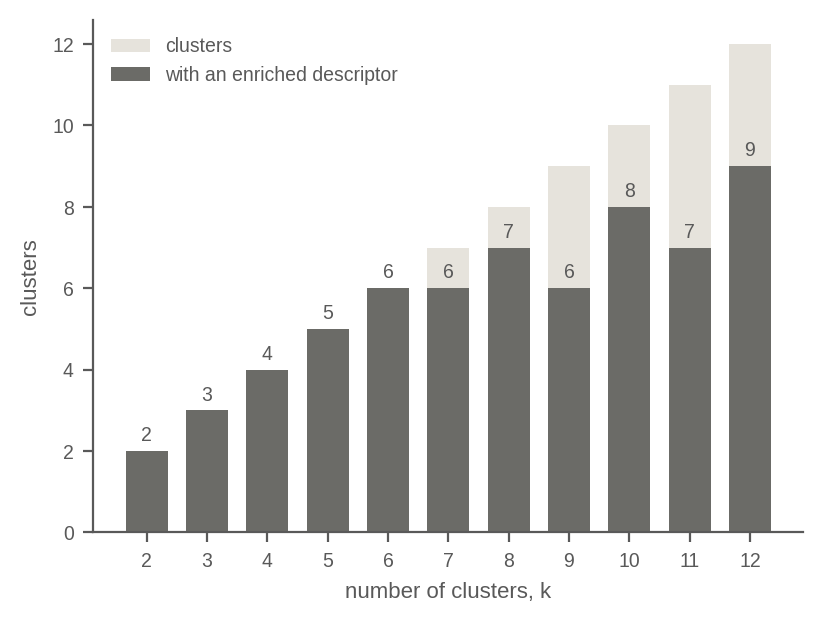

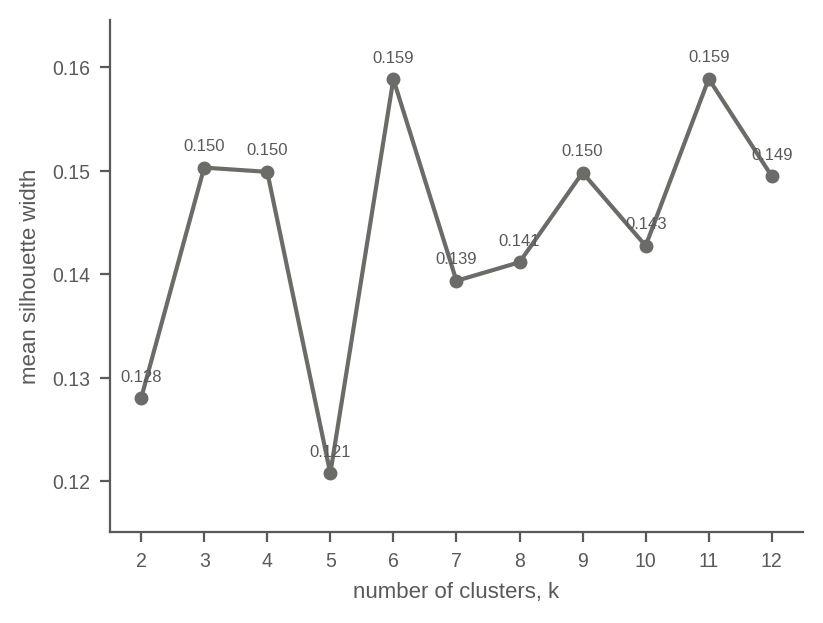

In [4]:
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
axis.bar(k_scan.k, k_scan.k, color="#e6e3dc", width=0.7, label="clusters")
axis.bar(k_scan.k, k_scan.clusters_with_descriptor, color=INK, width=0.7,
         label="with an enriched descriptor")
for k, n in zip(k_scan.k, k_scan.clusters_with_descriptor):
    axis.text(k, n + 0.15, str(n), ha="center", va="bottom", fontsize=7)
axis.set_xlabel("number of clusters, k")
axis.set_ylabel("clusters")
axis.set_xticks(k_scan.k)
axis.legend(frameon=False, fontsize=7, loc="upper left")
save(figure, FIGURES / "k_scan_perceptual_clusters.svg", show=True)

figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
axis.plot(k_scan.k, k_scan.silhouette, "o-", color=INK, ms=4)
for k, s in zip(k_scan.k, k_scan.silhouette):
    axis.annotate(f"{s:.3f}", (k, s), xytext=(0, 5), textcoords="offset points", ha="center",
                  va="bottom", fontsize=6)
axis.margins(y=0.15)
axis.set_xlabel("number of clusters, k")
axis.set_ylabel("mean silhouette width")
axis.set_xticks(k_scan.k)
save(figure, FIGURES / "k_scan_silhouette.svg", show=True)

### Against shuffled descriptors

Is "every cluster has an enriched descriptor" easy to reach by chance? The odour descriptor sets are
shuffled among the odorants 1,000 times, keeping the six clusters fixed.

In [5]:
tagged = [odorant for odorant in clustered_ids if odorant in tags_by_odorant]
rng = np.random.default_rng(0)
null_counts = []
for _ in range(1000):
    shuffled_sets = rng.permutation(len(tagged))
    shuffled_tags = {odorant: tags_by_odorant[tagged[j]] for odorant, j in zip(tagged, shuffled_sets)}
    enrichment = ac.tag_enrichment(clustered_ids, paper_labels, shuffled_tags)
    null_counts.append(ac.significant_enrichment(enrichment).cluster.nunique())
null_counts = np.array(null_counts)
shuffled = pd.DataFrame([dict(shuffles=len(null_counts),
                              mean_clusters_with_descriptor=null_counts.mean(),
                              shuffles_with_all_six=int((null_counts == 6).sum()),
                              shuffles_with_none=int((null_counts == 0).sum()))])
shuffled.to_csv(TABLES / "shuffled_descriptors.csv", index=False)
shuffled

,shuffles,mean_clusters_with_descriptor,shuffles_with_all_six,shuffles_with_none
0,1000,0.018,0,983


## 2. Odorants that sit between clusters

An odorant is assigned to its nearest medoid. When it is equally far from two medoids the
assignment is decided by medoid order, and an odorant that shares no receptor with any medoid is
at distance 1 from all six. Those odorants are counted here, and the descriptor enrichments are
recomputed without them.

In [6]:
medoids = []
for cluster in range(ac.N_CLUSTERS):
    members = np.where(paper_labels == cluster)[0]
    medoids.append(members[distance[np.ix_(members, members)].sum(1).argmin()])
distance_to_medoids = distance[:, medoids]
nearest = distance_to_medoids.min(1)
tied = np.isclose(distance_to_medoids, nearest[:, None]).sum(1) >= 2
unassignable = nearest >= 1 - 1e-9

keep = ~tied
enrichment_all = ac.significant_enrichment(ac.tag_enrichment(clustered_ids, paper_labels, tags_by_odorant))
enrichment_kept = ac.significant_enrichment(ac.tag_enrichment(clustered_ids[keep], paper_labels[keep],
                                                              tags_by_odorant))
pairs_all = set(zip(enrichment_all.cluster, enrichment_all.tag))
pairs_kept = set(zip(enrichment_kept.cluster, enrichment_kept.tag))

rows = []
for cluster in range(ac.N_CLUSTERS):
    in_cluster = paper_labels == cluster
    rows.append(dict(cluster=theme_of_cluster[cluster], odorants=int(in_cluster.sum()),
                     tied=int((tied & in_cluster).sum()), unassignable=int((unassignable & in_cluster).sum())))
ties = pd.DataFrame(rows)
ties.to_csv(TABLES / "tied_odorants.csv", index=False)
print(f"tied between two or more medoids: {tied.sum()} of {len(tied)}; at distance 1 from every medoid: {unassignable.sum()}")
print(f"significant descriptor enrichments: {len(pairs_all)} with them, {len(pairs_kept)} without them; "
      f"shared {len(pairs_all & pairs_kept)}")
ties

tied between two or more medoids: 33 of 687; at distance 1 from every medoid: 19
significant descriptor enrichments: 30 with them, 34 without them; shared 30


,cluster,odorants,tied,unassignable
0,Floral / Balsamic,127,20,19
1,Fruity / Fatty / Aldehydic,214,7,0
2,Acid / Dairy / Cheese,70,0,0
3,Smoky,108,6,0
4,Roasted / Phenolic / Spice,100,0,0
5,Fermented / Solvent,68,0,0


## 3. Re-clustering random subsamples

Each partition is redone 200 times on a random 80% of the odorants and 200 times on a random 80%
of the receptors, with the paper's settings. For every run: the agreement with the paper's
partition (adjusted Rand index over the odorants in both), each paper cluster's best match
(Jaccard index of members, the cluster-wise stability of Hennig 2007; above 0.75 is usually read as
stable, 0.6-0.75 as a real pattern with uncertain edges), and whether the perceptual reading
survives: how many clusters carry an enriched descriptor, which odour themes appear, and whether the
most acid-rich cluster is still the sour/acidic/cheesy one.

In [7]:
tasks = ([("odorants", 10_000 + seed, clustered_matrix) for seed in range(200)]
         + [("receptors", seed, clustered_matrix) for seed in range(200)])
with ProcessPoolExecutor(WORKERS) as pool:
    reclusterings = list(pool.map(rc.recluster_subsample, tasks))

rows = []
for what, seed, kept, labels in reclusterings:
    perception = rc.cluster_perception(clustered_ids[kept], labels, tags_by_odorant, is_acid[kept])
    row = dict(subsample=what, seed=seed,
               adjusted_rand_index=adjusted_rand_score(paper_labels[kept], labels),
               clusters_with_descriptor=perception["clusters_with_descriptor"],
               acid_cluster_pct_acid=perception["acid_cluster_pct_acid"],
               acid_cluster_is_sour=perception["acid_cluster_is_sour"],
               themes="; ".join(sorted(perception["themes"])))
    for cluster in range(ac.N_CLUSTERS):
        members = set(np.where(paper_labels[kept] == cluster)[0])
        best = max(len(members & set(np.where(labels == c)[0])) / len(members | set(np.where(labels == c)[0]))
                   for c in np.unique(labels))
        row[f"jaccard_{theme_of_cluster[cluster]}"] = best
    rows.append(row)
subsamples = pd.DataFrame(rows)
subsamples.to_csv(TABLES / "subsample_reclustering.csv", index=False)

summary_rows = []
for what, runs in subsamples.groupby("subsample"):
    row = dict(subsample=what, runs=len(runs),
               median_adjusted_rand_index=runs.adjusted_rand_index.median(),
               pct_runs_all_six_perceptual=100 * (runs.clusters_with_descriptor == 6).mean(),
               pct_runs_acid_cluster_sour=100 * runs.acid_cluster_is_sour.mean(),
               median_acid_cluster_pct_acid=runs.acid_cluster_pct_acid.median())
    for cluster in range(ac.N_CLUSTERS):
        row[f"mean_jaccard_{theme_of_cluster[cluster]}"] = runs[f"jaccard_{theme_of_cluster[cluster]}"].mean()
    summary_rows.append(row)
subsample_summary = pd.DataFrame(summary_rows)
subsample_summary.to_csv(TABLES / "subsample_summary.csv", index=False)
subsample_summary.round(2).T

,0,1
subsample,odorants,receptors
runs,200,200
median_adjusted_rand_index,0.79,0.51
pct_runs_all_six_perceptual,51.5,64.5
pct_runs_acid_cluster_sour,85.5,81.5
median_acid_cluster_pct_acid,58.88,49.74
mean_jaccard_Floral / Balsamic,0.75,0.61
mean_jaccard_Fruity / Fatty / Aldehydic,0.79,0.71
mean_jaccard_Acid / Dairy / Cheese,0.63,0.47
mean_jaccard_Smoky,0.64,0.47


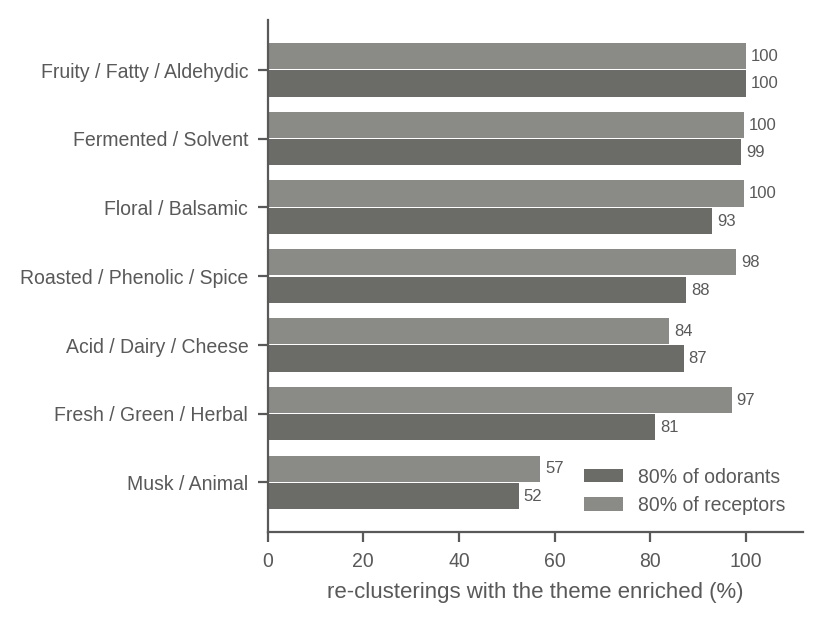

subsample,odorants,receptors
theme,,
Musk / Animal,52.0,57.0
Fresh / Green / Herbal,81.0,97.0
Acid / Dairy / Cheese,87.0,84.0
Roasted / Phenolic / Spice,88.0,98.0
Floral / Balsamic,93.0,100.0
Fermented / Solvent,99.0,100.0
Fruity / Fatty / Aldehydic,100.0,100.0


In [8]:
theme_rows = []
for what, runs in subsamples.groupby("subsample"):
    counts = Counter(theme for themes in runs.themes for theme in themes.split("; ") if theme)
    for _, theme_name, _ in ac.THEME_RULES:
        theme_rows.append(dict(subsample=what, theme=theme_name, pct_runs=100 * counts[theme_name] / len(runs)))
theme_recurrence = pd.DataFrame(theme_rows).pivot(index="theme", columns="subsample", values="pct_runs")
theme_recurrence = theme_recurrence.sort_values("odorants")
theme_recurrence.to_csv(TABLES / "theme_recurrence.csv")

figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
positions = np.arange(len(theme_recurrence))
for offset, (what, colour) in zip([-0.2, 0.2], [("odorants", INK), ("receptors", MUTED)]):
    values = theme_recurrence[what].values
    axis.barh(positions + offset, values, height=0.38, color=colour, label=f"80% of {what}")
    for y, value in zip(positions + offset, values):
        axis.text(value + 1, y, f"{value:.0f}", va="center", fontsize=6)
axis.set_yticks(positions)
axis.set_yticklabels(theme_recurrence.index, fontsize=7)
axis.set_xlim(0, 112)
axis.set_xlabel("re-clusterings with the theme enriched (%)", fontsize=8)
axis.legend(frameon=False, fontsize=7, loc="lower right")
save(figure, FIGURES / "theme_recurrence.svg", show=True)
theme_recurrence.round(0)

Boundaries move: with 20% of the odorants left out the partition stays close to the paper's
(median adjusted Rand index about 0.8), with 20% of the receptors left out it moves more (about 0.5).
What does not move is the reading. The fruity/fatty, fermented, floral and roasted themes are
enriched in almost every re-clustering, an acid-rich cluster carrying sour, acidic or cheesy appears
in over 80% of them, and the musk/animal theme, which is not one of the paper's six, appears in
about half.

## 4. Another clustering method

Hierarchical clustering on the same Jaccard distance. Average and complete linkage are not usable
here: many odorant pairs are at exactly the same distance, the trees chain, and a cut into six
leaves one cluster with almost every odorant. Ward linkage on the first 20 principal coordinates
of the distance does give six usable clusters.

In [9]:
rows = []
for method in ["average", "complete"]:
    labels = fcluster(linkage(squareform(distance, checks=False), method), 6, "maxclust") - 1
    perception = rc.cluster_perception(clustered_ids, labels, tags_by_odorant, is_acid)
    rows.append(dict(method=f"{method} linkage", largest_cluster=int(np.bincount(labels).max()),
                     adjusted_rand_index=adjusted_rand_score(paper_labels, labels),
                     clusters_with_descriptor=perception["clusters_with_descriptor"],
                     acid_cluster_is_sour=perception["acid_cluster_is_sour"]))
coordinates, _ = ac.pcoa(distance)
labels = fcluster(linkage(coordinates[:, :20], "ward"), 6, "maxclust") - 1
perception = rc.cluster_perception(clustered_ids, labels, tags_by_odorant, is_acid)
rows.append(dict(method="Ward linkage, 20 principal coordinates", largest_cluster=int(np.bincount(labels).max()),
                 adjusted_rand_index=adjusted_rand_score(paper_labels, labels),
                 clusters_with_descriptor=perception["clusters_with_descriptor"],
                 acid_cluster_is_sour=perception["acid_cluster_is_sour"]))
other_methods = pd.DataFrame(rows)
other_methods.to_csv(TABLES / "other_methods.csv", index=False)
other_methods.round(2)

,method,largest_cluster,adjusted_rand_index,clusters_with_descriptor,acid_cluster_is_sour
0,average linkage,679,0.00,0,False
1,complete linkage,687,0.00,0,False
2,"Ward linkage, 20 principal coordinates",159,0.37,6,True


## 5. The same question without clusters

If odorants that activate similar receptor combinations smell alike, the distance between two
odorants' barcodes should rise with the distance between their odour descriptors, over all pairs.
This is a Mantel test (Spearman) on the odorants that have both a call and a descriptor; the
partial test removes what structural distance (1 - Tanimoto, Morgan fingerprints, radius 2, 2,048
bits) explains of both, since the model reads structure. 999 permutations.

In [10]:
with_tags = np.array([odorant in tags_by_odorant for odorant in clustered_ids])
tagged_ids = clustered_ids[with_tags]
barcode_distance = distance[np.ix_(with_tags, with_tags)]

descriptor_sets = [set(tags_by_odorant[odorant]) for odorant in tagged_ids]
n = len(tagged_ids)
descriptor_distance = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        union = len(descriptor_sets[i] | descriptor_sets[j])
        shared = len(descriptor_sets[i] & descriptor_sets[j])
        descriptor_distance[i, j] = descriptor_distance[j, i] = 1 - shared / union if union else 0.0

fingerprints = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smiles_by_odorant[odorant]), 2, 2048)
                for odorant in tagged_ids]
structure_distance = np.array([1 - np.array(DataStructs.BulkTanimotoSimilarity(fp, fingerprints))
                               for fp in fingerprints])

mantel = pd.DataFrame([rc.mantel_test(barcode_distance, descriptor_distance, structure_distance)])
mantel.to_csv(TABLES / "mantel_barcode_descriptor.csv", index=False)
mantel.round(4).T

,0
odorants,529.0000
pairs,139656.0000
rho_barcode_descriptor,0.1397
P,0.0010
rho_partial_on_structure,0.0996
P_partial,0.0010
rho_structure_descriptor,0.2635
permutations,999.0000


Over all pairs, odorants with more similar barcodes have more similar odour descriptors, and the
association remains when structural similarity is held fixed. The perceptual reading of the code
therefore does not rest on the choice of six clusters, or on clustering at all.